In [1]:
import wfdb
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.signal import medfilt
import pywt
from ecgdetectors import Detectors

In [2]:
scd_data = {'./data/scddb/30': '07:54:33',
 './data/scddb/31': '13:42:24',
 './data/scddb/32': '16:45:18',
 './data/scddb/33': '04:46:19',
 './data/scddb/34': '06:35:44',
 './data/scddb/35': '24:34:56',
 './data/scddb/36': '18:59:01',
 './data/scddb/37': '01:31:13',
 './data/scddb/38': '08:01:54',
 './data/scddb/39': '04:37:51',
 './data/scddb/41': '02:59:24',
 './data/scddb/43': '15:37:11',
 './data/scddb/44': '19:38:45',
 './data/scddb/45': '18:09:17',
 './data/scddb/46': '03:41:47',
 './data/scddb/47': '06:13:01',
 './data/scddb/48': '02:29:40',
 './data/scddb/50': '11:45:43',
 './data/scddb/51': '22:58:23',
 './data/scddb/52': '02:32:40'}

fs = 250

In [3]:
def hms_to_seconds(hms):
    h, m, s = hms.split(':')
    return int(h)*3600 + int(m)*60 + int(s)

In [4]:
def extract_before_onset_VF(vfon_dict, minutes_before=60):
    ecg_data_map = {} 

    for record_path, vf_onset_str in vfon_dict.items():
        # record_path might be '.data/scddb/30'
        record_dir, record_name = os.path.split(record_path)

        # 2) Convert dictionary's VF onset to seconds
        vf_onset_original_sec = hms_to_seconds(vf_onset_str)

        vfon_onset_original_sample = vf_onset_original_sec * fs

        seg_len_samples = int(minutes_before * 60 * fs)

        start_sample = vfon_onset_original_sample - seg_len_samples

         # read .dat between those sample indices
        try:
            #record_dat_path = os.path.join(record_dir, record_name)  # base path
            record_path_dat = os.path.join(record_dir, record_name)
            segment = wfdb.rdrecord(record_path_dat, sampfrom=start_sample, sampto=vfon_onset_original_sample)
            
        except Exception as e:
            print(f"[ERROR] Failed to read record {record_dat_path}: {e}")
            continue

        # Retrieve the raw signal data as a NumPy array
        if segment.p_signal is not None:
            arr = segment.p_signal[:,0]
            ecg_data_map[record_name] = arr
            print(f"[OK] Extracted 60-min for {record_name}: shape={arr.shape}")
        else:
            print(f"[WARNING] No p_signal found for {record_name}")

    return ecg_data_map

In [5]:
x = extract_before_onset_VF(scd_data, minutes_before=60)

[OK] Extracted 60-min for 30: shape=(900000,)
[OK] Extracted 60-min for 31: shape=(900000,)
[OK] Extracted 60-min for 32: shape=(900000,)
[OK] Extracted 60-min for 33: shape=(900000,)
[OK] Extracted 60-min for 34: shape=(900000,)
[OK] Extracted 60-min for 35: shape=(900000,)
[OK] Extracted 60-min for 36: shape=(900000,)
[OK] Extracted 60-min for 37: shape=(900000,)
[OK] Extracted 60-min for 38: shape=(900000,)
[OK] Extracted 60-min for 39: shape=(900000,)
[OK] Extracted 60-min for 41: shape=(900000,)
[OK] Extracted 60-min for 43: shape=(900000,)
[OK] Extracted 60-min for 44: shape=(900000,)
[OK] Extracted 60-min for 45: shape=(900000,)
[OK] Extracted 60-min for 46: shape=(900000,)
[OK] Extracted 60-min for 47: shape=(900000,)
[OK] Extracted 60-min for 48: shape=(900000,)
[OK] Extracted 60-min for 50: shape=(900000,)
[OK] Extracted 60-min for 51: shape=(900000,)
[OK] Extracted 60-min for 52: shape=(900000,)


## Baseline wander eliminate

In [6]:
def get_median_filter_width(sampling_rate, duration):
    res = int( sampling_rate*duration )
    res += ((res%2) - 1) # needs to be an odd number
    return res

ms_flt_array = [0.2,0.6]    #<-- length of baseline fitting filters (in seconds)
mfa = np.zeros(len(ms_flt_array), dtype='int')
for i in range(0, len(ms_flt_array)):
    mfa[i] = get_median_filter_width(fs,ms_flt_array[i])

def filter_signal(X):
    global mfa
    X0 = X  #read orignal signal
    for mi in range(0,len(mfa)):
        X0 = medfilt(X0,mfa[mi]) # apply median filter one by one on top of each other
    X0 = np.subtract(X,X0)  # finally subtract from orignal signal
    return X0

In [7]:
baselinewanderGLOBAL20 = {}

for i, j in x.items():
    baselinewanderGLOBAL20[i] = filter_signal(x[i])
    print(x[i].shape, baselinewanderGLOBAL20[i].shape)

(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)


In [8]:
# Range bounds as float64
low = np.float64(-0.9525)
high = np.float64(1.05875)

# Fill NaNs with random float64 values in range for specific keys
for key in ['35', '41', '52']:
    arr = baselinewanderGLOBAL20[key]
    nan_mask = np.isnan(arr)
    num_nans = np.sum(nan_mask)
    if num_nans > 0:
        # Generate random float64 numbers
        random_values = np.random.uniform(low, high, size=num_nans).astype(np.float64)
        # Replace NaNs
        arr[nan_mask] = random_values
        baselinewanderGLOBAL20[key] = arr  # Save back to dict

In [9]:
# List of keys with NaNs from the previous check
keys_with_nan = ['30', '35', '41', '52']

# Count NaNs per key
nan_counts = {}
for key in keys_with_nan:
    arr = baselinewanderGLOBAL20[key]
    nan_counts[key] = np.sum(np.isnan(arr))

# Print results
for key, count in nan_counts.items():
    print(f"Key {key} has {count} NaN values.")

Key 30 has 0 NaN values.
Key 35 has 0 NaN values.
Key 41 has 0 NaN values.
Key 52 has 0 NaN values.


## Denoisement

In [10]:
def denoise_signal(X, dwt_transform, dlevels, cutoff_low, cutoff_high):
    coeffs = pywt.wavedec(X, dwt_transform, level=dlevels)   # wavelet transform 'bior4.4'
    # scale 0 to cutoff_low 
    for ca in range(0,cutoff_low):
        coeffs[ca]=np.multiply(coeffs[ca],[0.0])
    # scale cutoff_high to end
    for ca in range(cutoff_high, len(coeffs)):
        coeffs[ca]=np.multiply(coeffs[ca],[0.0])
    Y = pywt.waverec(coeffs, dwt_transform) # inverse wavelet transform
    return Y  

In [11]:
denoisedGLOBAL20 = {}

for key, val in baselinewanderGLOBAL20.items():
    denoisedGLOBAL20[key] = denoise_signal(baselinewanderGLOBAL20[key],'bior4.4', 9 , 1 , 7)
    print(baselinewanderGLOBAL20[key].shape, denoisedGLOBAL20[key].shape)

(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)
(900000,) (900000,)


In [12]:
# List of keys with NaNs from the previous check
keys_with_nan = ['30', '35', '41', '52']

# Count NaNs per key
nan_counts = {}
for key in keys_with_nan:
    arr = denoisedGLOBAL20[key]
    nan_counts[key] = np.sum(np.isnan(arr))

# Print results
for key, count in nan_counts.items():
    print(f"Key {key} has {count} NaN values.")


Key 30 has 0 NaN values.
Key 35 has 0 NaN values.
Key 41 has 0 NaN values.
Key 52 has 0 NaN values.


In [13]:
def check_non_numeric(data_dict):
    issues = {}
    for key, arr in data_dict.items():
        if not isinstance(arr, np.ndarray):
            issues[key] = 'Not a numpy array'
            continue
        if arr.dtype == object:
            # May contain mixed types like None or strings
            if any(not isinstance(x, (int, float, np.integer, np.floating)) for x in arr):
                issues[key] = 'Contains non-numeric types (e.g., None or string)'
                continue
        if np.any(np.isnan(arr)):
            issues[key] = 'Contains NaN'
    return issues

# Run the check
problems = check_non_numeric(denoisedGLOBAL20)

# Report
if problems:
    print("Found non-numeric issues in the following keys:")
    for k, v in problems.items():
        print(f"  {k}: {v}")
else:
    print("All values are valid numbers.")

All values are valid numbers.


In [14]:
def check_non_numeric(data_dict):
    issues = {}
    for key, arr in data_dict.items():
        if not isinstance(arr, np.ndarray):
            issues[key] = 'Not a numpy array'
            continue
        if arr.dtype == object:
            # May contain mixed types like None or strings
            if any(not isinstance(x, (int, float, np.integer, np.floating)) for x in arr):
                issues[key] = 'Contains non-numeric types (e.g., None or string)'
                continue
        if np.any(np.isnan(arr)):
            issues[key] = 'Contains NaN'
    return issues

# Run the check
problems = check_non_numeric(baselinewanderGLOBAL20)

# Report
if problems:
    print("Found non-numeric issues in the following keys:")
    for k, v in problems.items():
        print(f"  {k}: {v}")
else:
    print("All values are valid numbers.")

All values are valid numbers.


In [15]:
# List of keys with NaNs from the previous check
keys_with_nan = ['30', '35', '41', '52']

# Count NaNs per key
nan_counts = {}
for key in keys_with_nan:
    arr = denoisedGLOBAL20[key]
    nan_counts[key] = np.sum(np.isnan(arr))

# Print results
for key, count in nan_counts.items():
    print(f"Key {key} has {count} NaN values.")


Key 30 has 0 NaN values.
Key 35 has 0 NaN values.
Key 41 has 0 NaN values.
Key 52 has 0 NaN values.


In [16]:
# List of keys with NaNs from the previous check
keys_with_nan = ['30', '35', '41', '52']

# Count NaNs per key
nan_counts = {}
for key in keys_with_nan:
    arr = baselinewanderGLOBAL20[key]
    nan_counts[key] = np.sum(np.isnan(arr))

# Print results
for key, count in nan_counts.items():
    print(f"Key {key} has {count} NaN values.")


Key 30 has 0 NaN values.
Key 35 has 0 NaN values.
Key 41 has 0 NaN values.
Key 52 has 0 NaN values.


## R peak detection

In [17]:
from ecgdetectors import Detectors
BASIC_SRATE = 250

In [18]:
signal_pad_samples = 10
signal_pad = np.zeros(signal_pad_samples) # pad one sec to detect initial peaks properly
detectors = Detectors(BASIC_SRATE)

In [19]:
detectors = {
            'pan_tompkins_detector':[detectors.pan_tompkins_detector, []],
            'hamilton_detector':[detectors.hamilton_detector, []],
            'christov_detector':[detectors.christov_detector, []],
            'engzee_detector':[detectors.engzee_detector, []],
            'swt_detector':[detectors.swt_detector, []],
            'two_average_detector':[detectors.two_average_detector, []],
            }

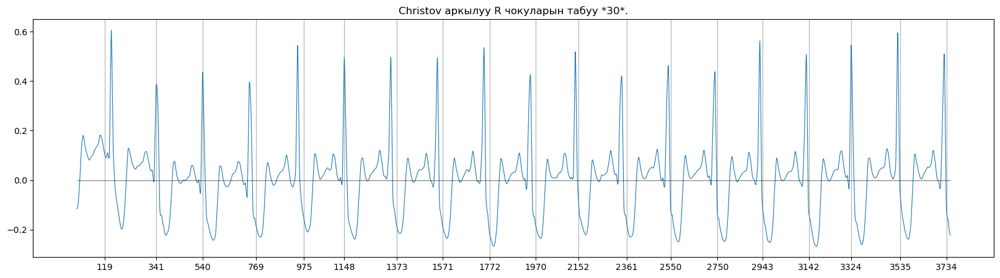

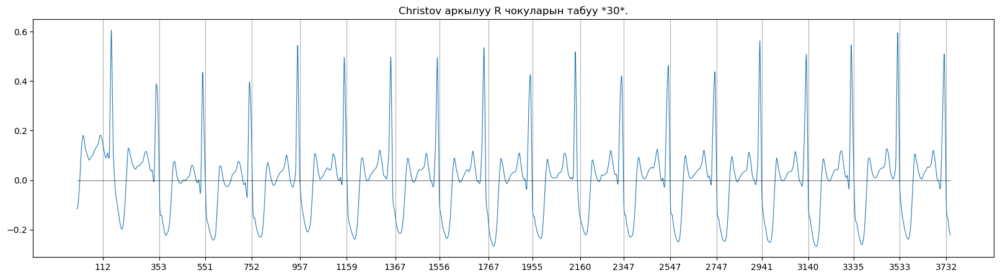

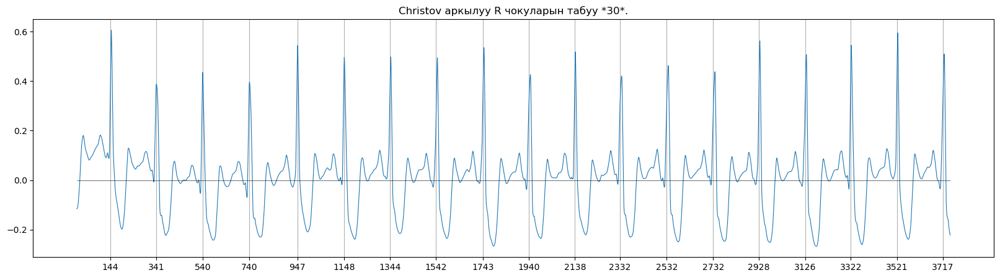

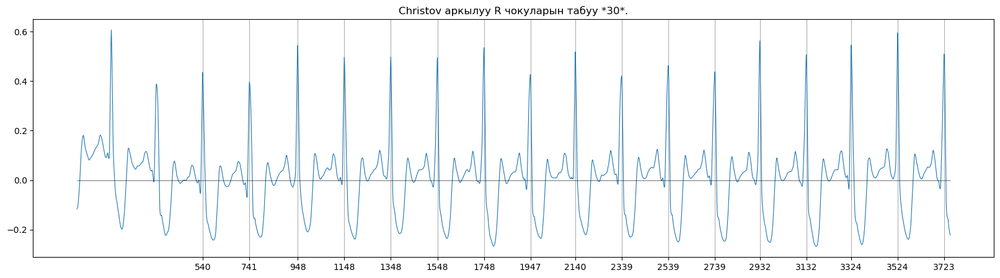

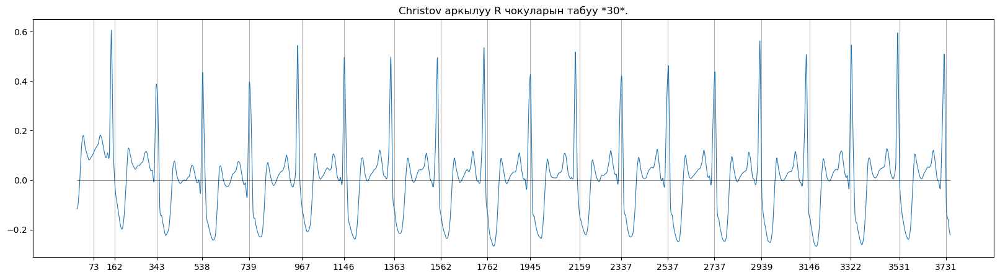

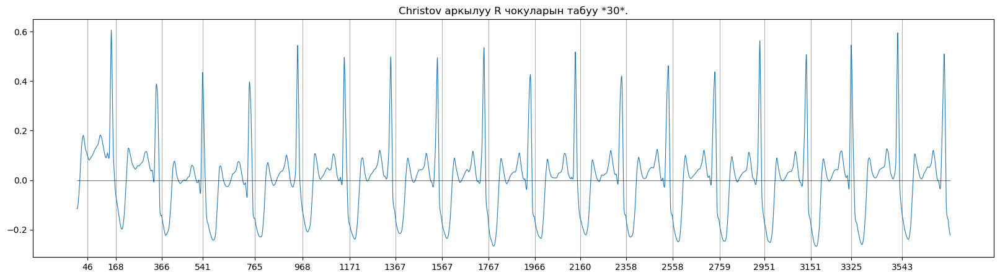

In [21]:
example = denoisedGLOBAL20['30'][:3750]

for kd in detectors.keys():
    vd = detectors[kd]
    r_peaks = np.array(vd[0](np.hstack((signal_pad,example)))) - signal_pad_samples
    vd[1] = r_peaks
    plt.figure(figsize=(20,5))
    plt.title('Christov аркылуу R чокуларын табуу *30*.')
    plt.plot(example,color='tab:blue',linewidth=0.8)
    plt.hlines(0,0,3750,color='black', linewidth=0.4)
    plt.xticks(r_peaks)
    plt.grid(axis='x')
    plt.savefig(f'./img/rpeak{kd}_christov.png', dpi=300, bbox_inches='tight')
    plt.show()

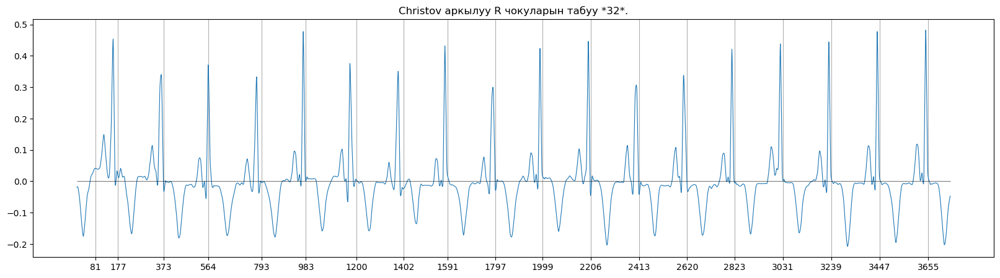

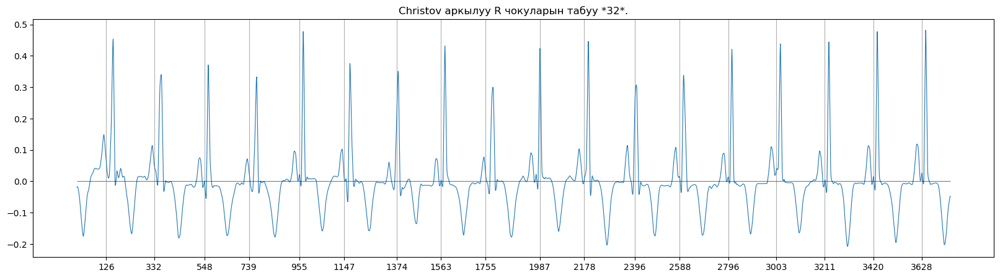

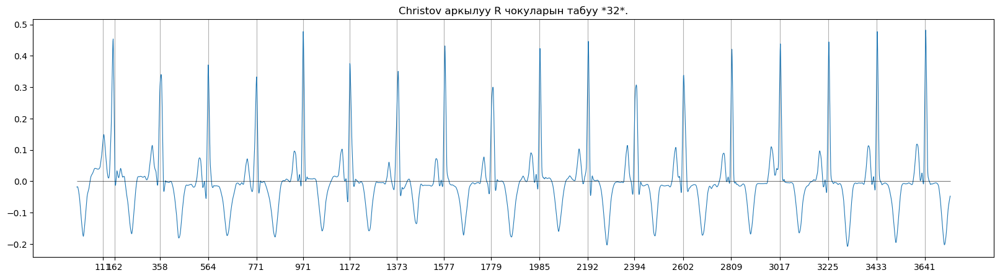

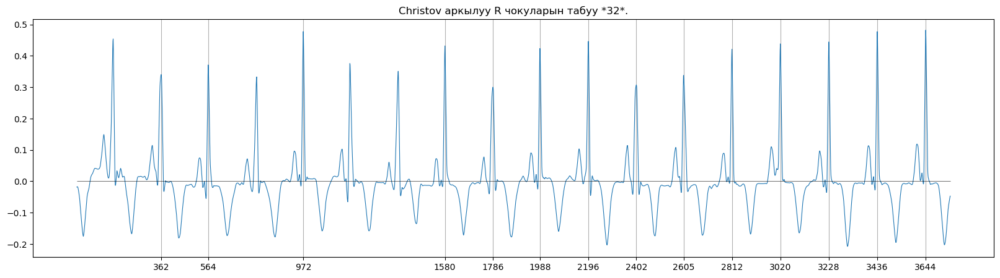

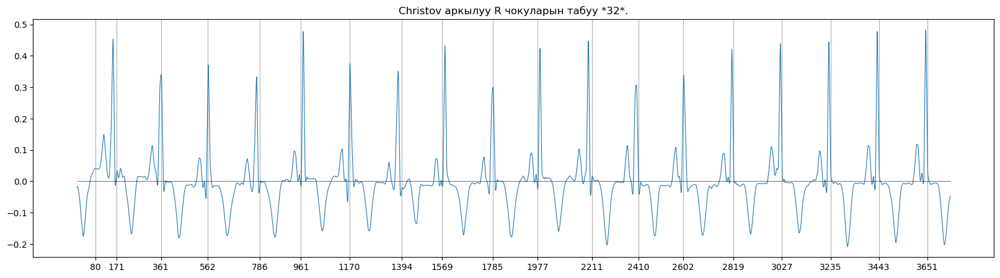

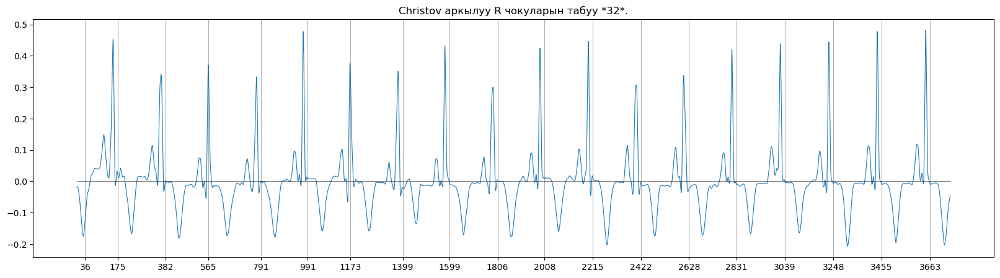

In [22]:
example = denoisedGLOBAL20['32'][:3750]

for kd in detectors.keys():
    vd = detectors[kd]
    r_peaks = np.array(vd[0](np.hstack((signal_pad,example)))) - signal_pad_samples
    vd[1] = r_peaks
    plt.figure(figsize=(20,5))
    plt.title('Christov аркылуу R чокуларын табуу *32*.')
    plt.plot(example,color='tab:blue',linewidth=0.8)
    plt.hlines(0,0,3750,color='black', linewidth=0.4)
    plt.xticks(r_peaks)
    plt.grid(axis='x')
    plt.savefig(f'./img/32_rpeak{kd}_christov.png', dpi=300, bbox_inches='tight')
    plt.show()

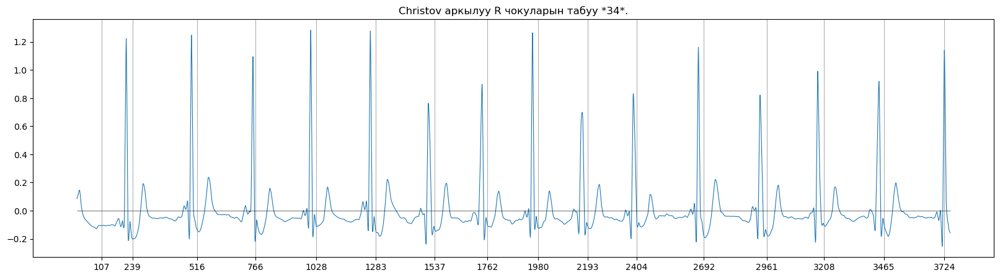

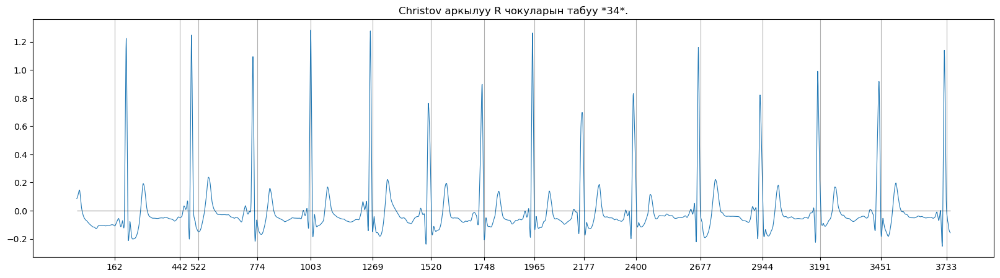

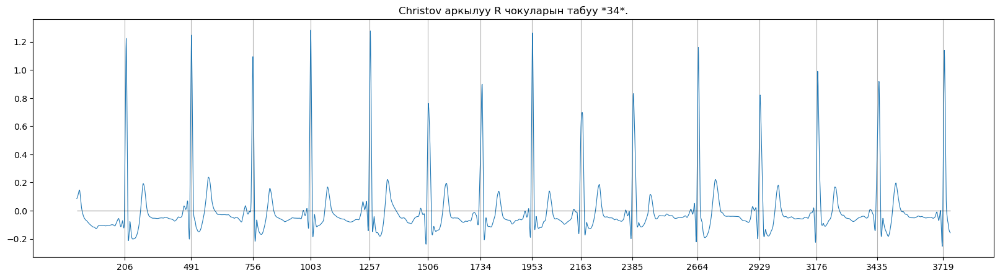

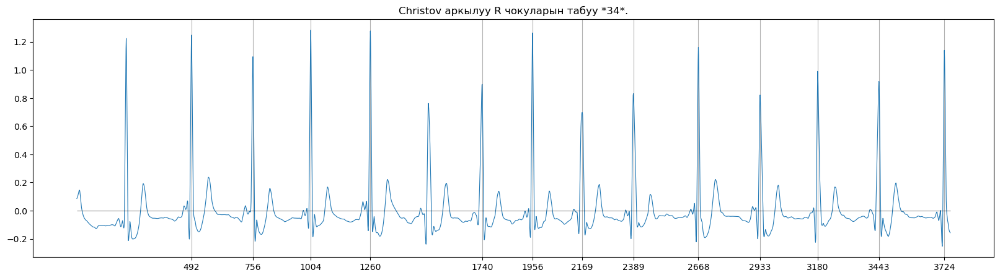

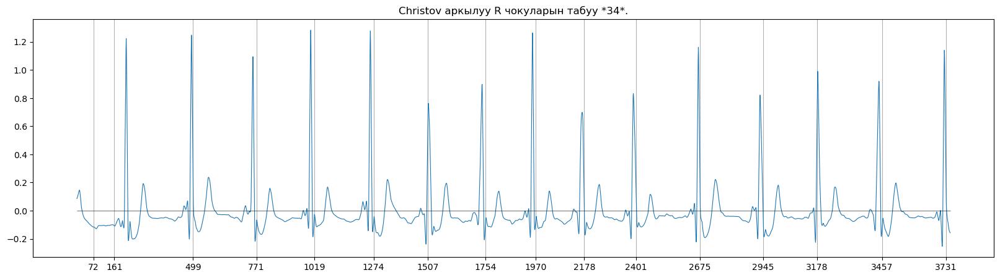

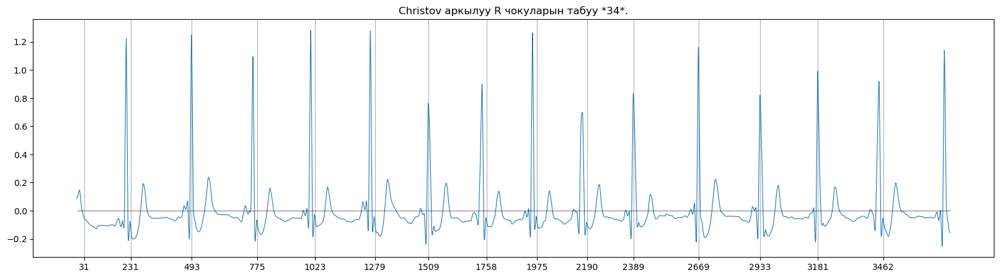

In [30]:
example = denoisedGLOBAL20['35'][:3750]

for kd in detectors.keys():
    vd = detectors[kd]
    r_peaks = np.array(vd[0](np.hstack((signal_pad,example)))) - signal_pad_samples
    vd[1] = r_peaks
    plt.figure(figsize=(20,5))
    plt.title('Christov аркылуу R чокуларын табуу *34*.')
    plt.plot(example,color='tab:blue',linewidth=0.8)
    plt.hlines(0,0,3750,color='black', linewidth=0.4)
    plt.xticks(r_peaks)
    plt.grid(axis='x')
    plt.savefig(f'./img/34_rpeak{kd}_christov.png', dpi=300, bbox_inches='tight')
    plt.show()

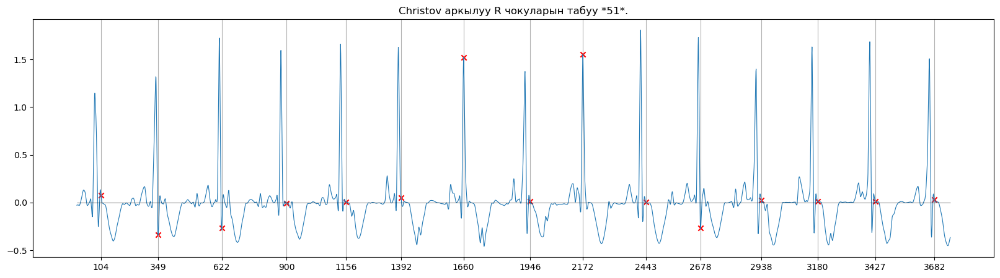

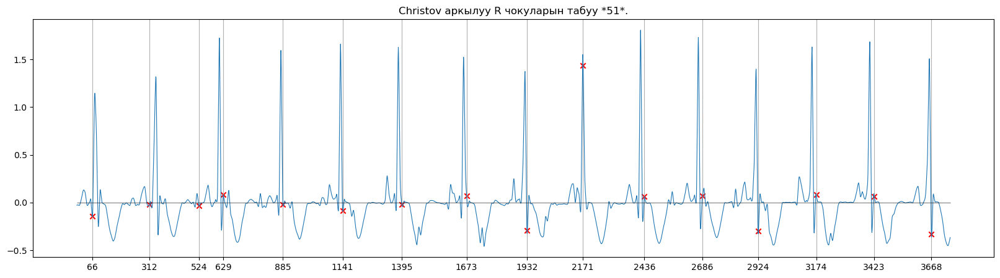

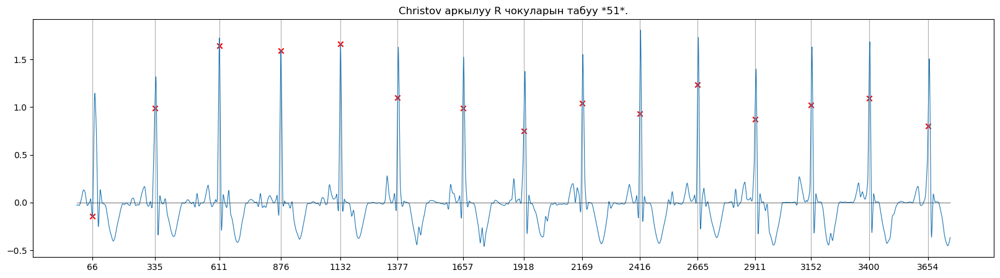

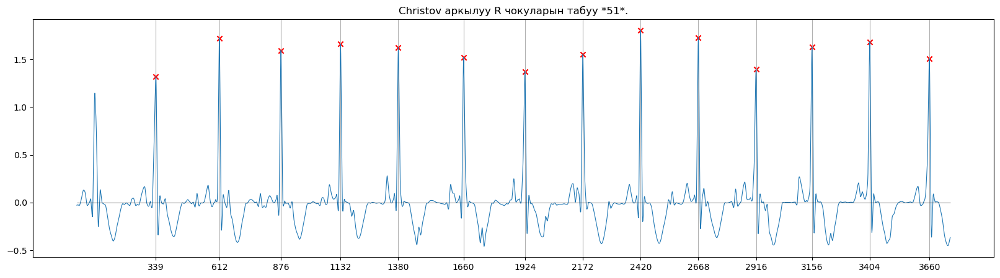

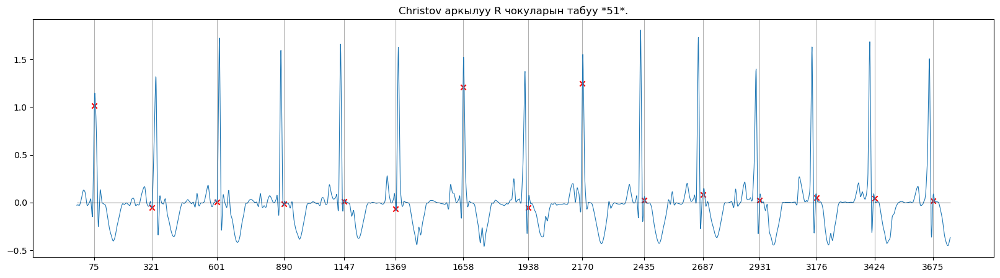

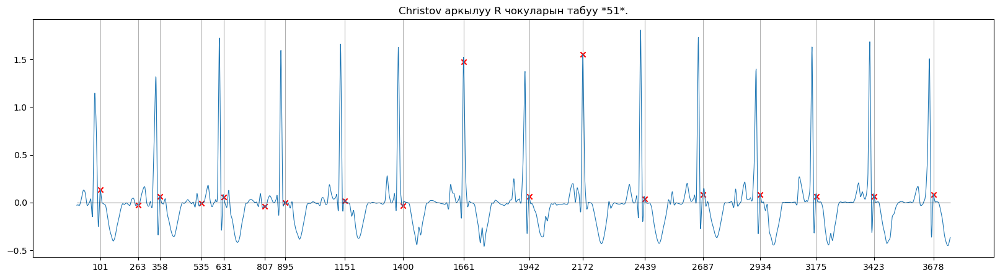

In [50]:
example = denoisedGLOBAL20['51'][:3750]

for kd in detectors.keys():
    vd = detectors[kd]
    r_peaks = np.array(vd[0](np.hstack((signal_pad,example)))) - signal_pad_samples
    vd[1] = r_peaks
    plt.figure(figsize=(20,5))
    plt.title('Christov аркылуу R чокуларын табуу *51*.')
    plt.plot(example,color='tab:blue',linewidth=0.8)
    plt.scatter(r_peaks, example[r_peaks], color='red', marker='x', label='R-чокулары')
    plt.hlines(0,0,3750,color='black', linewidth=0.4)
    plt.xticks(r_peaks)
    plt.grid(axis='x')
    plt.savefig(f'./img/34xxxxx_rpeak{kd}_christov.png', dpi=300, bbox_inches='tight')
    plt.show()

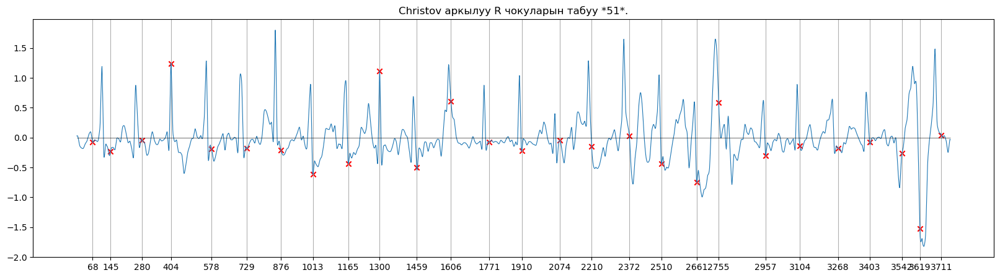

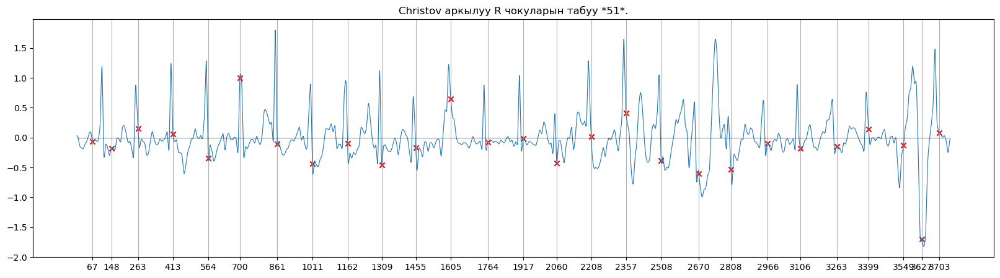

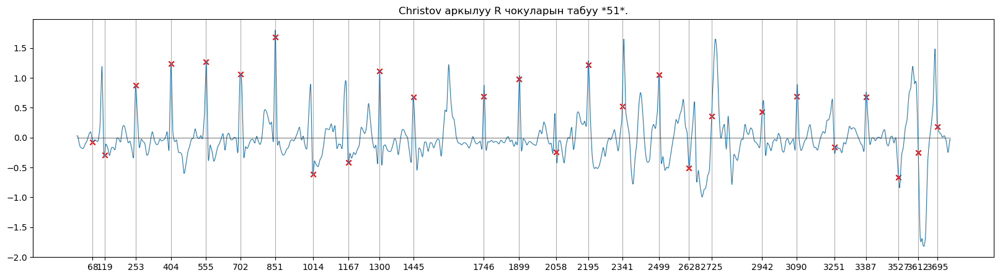

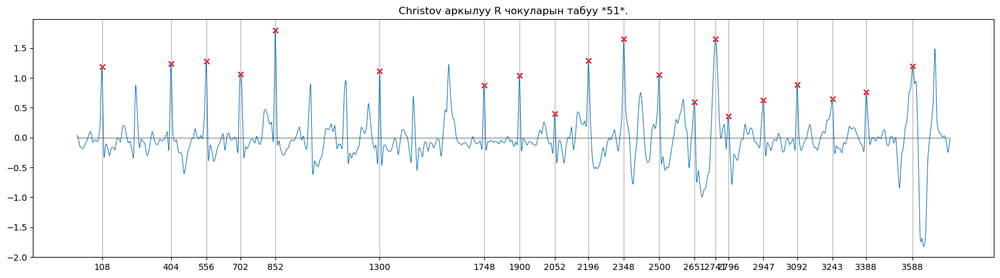

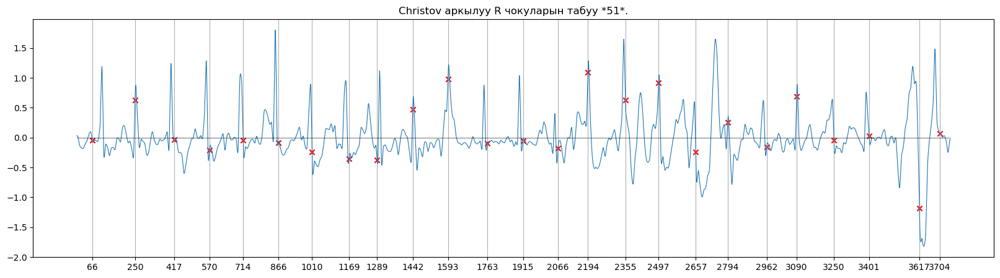

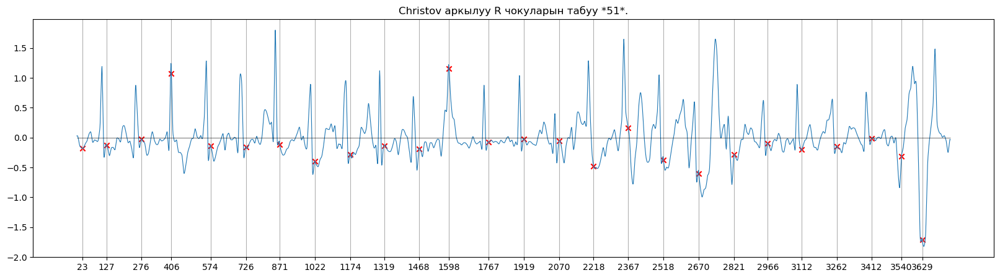

In [51]:
example = denoisedGLOBAL20['52'][:3750]

for kd in detectors.keys():
    vd = detectors[kd]
    r_peaks = np.array(vd[0](np.hstack((signal_pad,example)))) - signal_pad_samples
    vd[1] = r_peaks
    plt.figure(figsize=(20,5))
    plt.title('Christov аркылуу R чокуларын табуу *51*.')
    plt.plot(example,color='tab:blue',linewidth=0.8)
    plt.scatter(r_peaks, example[r_peaks], color='red', marker='x', label='R-чокулары')
    plt.hlines(0,0,3750,color='black', linewidth=0.4)
    plt.xticks(r_peaks)
    plt.grid(axis='x')
    #plt.savefig(f'./img/34xxxxx_rpeak{kd}_christov.png', dpi=300, bbox_inches='tight')
    plt.show()

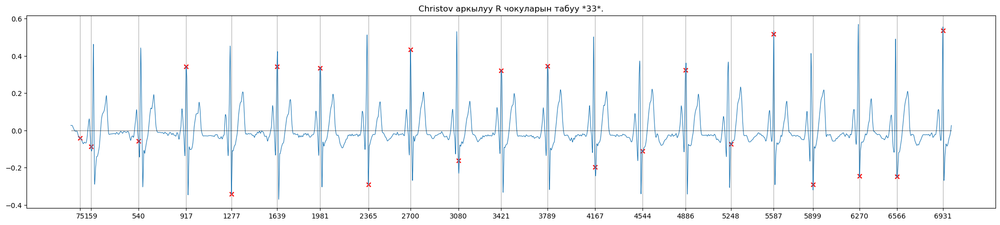

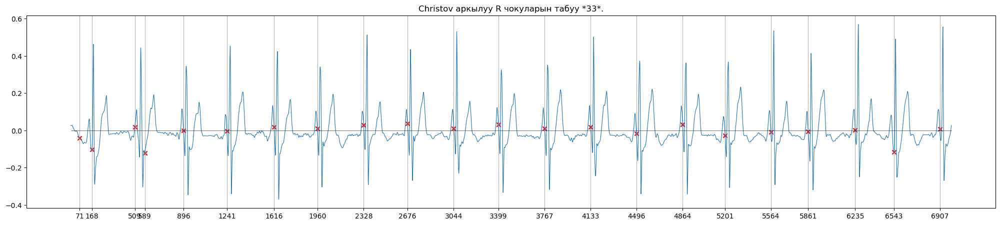

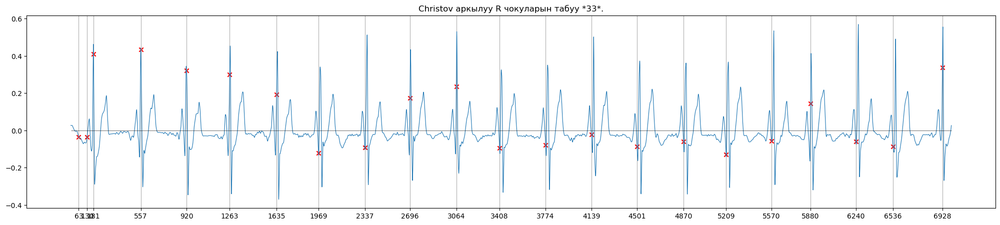

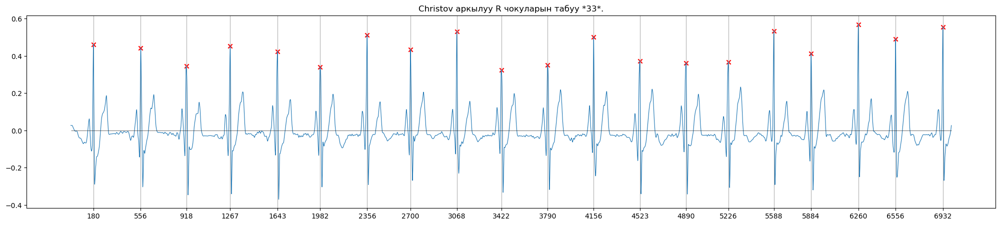

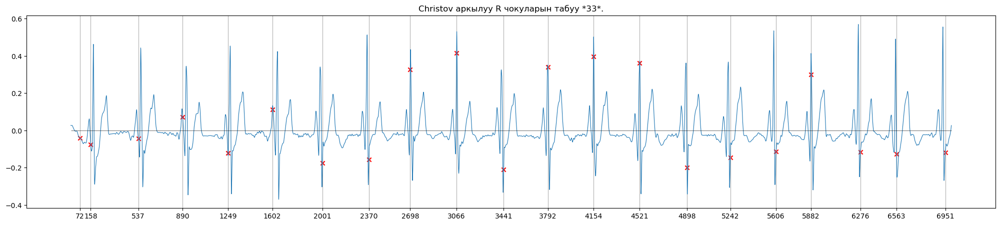

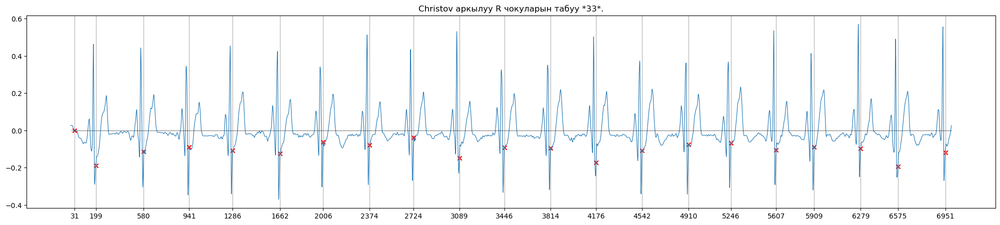

In [60]:
example = denoisedGLOBAL20['33'][:7000]

for kd in detectors.keys():
    vd = detectors[kd]
    r_peaks = np.array(vd[0](np.hstack((signal_pad,example)))) - signal_pad_samples
    vd[1] = r_peaks
    plt.figure(figsize=(25,5))
    plt.title('Christov аркылуу R чокуларын табуу *33*.')
    plt.plot(example,color='tab:blue',linewidth=0.8)
    plt.scatter(r_peaks, example[r_peaks], color='red', marker='x', label='R-чокулары')
    plt.hlines(0,0,7000,color='black', linewidth=0.4)
    plt.xticks(r_peaks)
    plt.grid(axis='x')
    plt.savefig(f'./img/33xxxxx_rpeak{kd}_christov.png', dpi=300, bbox_inches='tight')
    plt.show()

In [40]:
detecs = Detectors(BASIC_SRATE)
detecs = {
            'christov_detector':[detecs.christov_detector, []],
            'engzee_detector':[detecs.engzee_detector, []],
            }

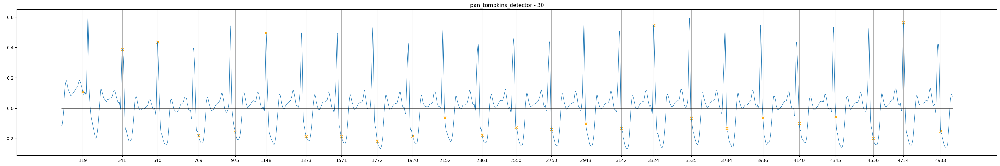

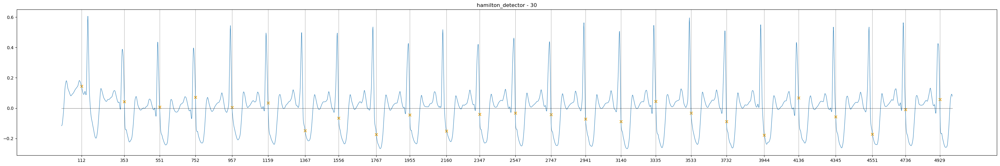

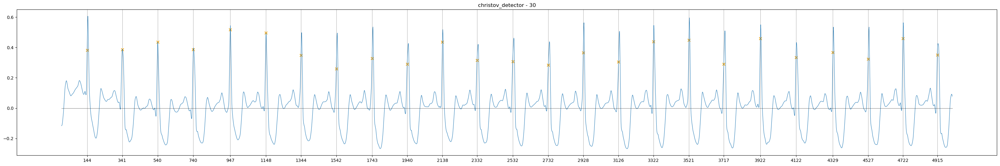

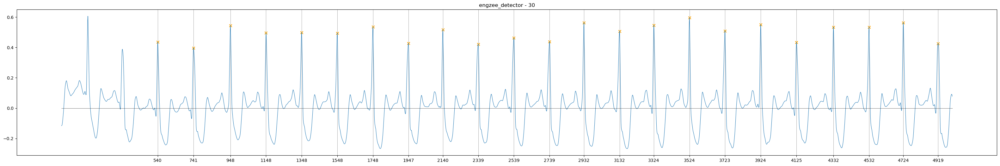

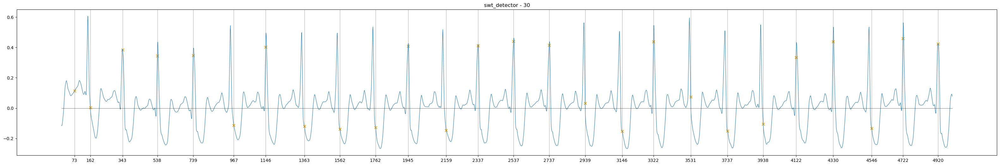

...

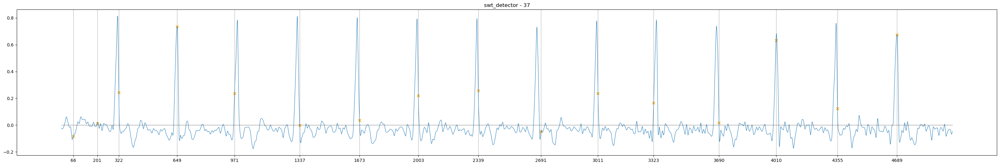

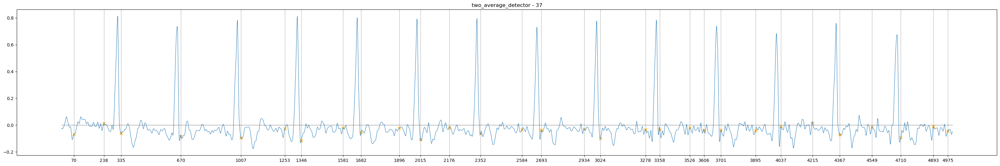

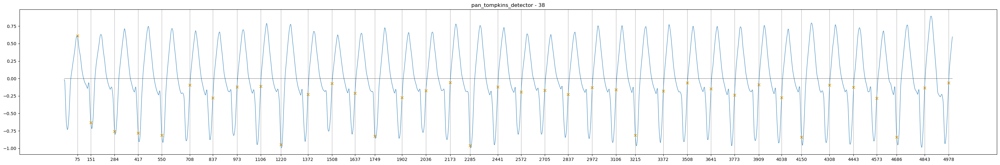

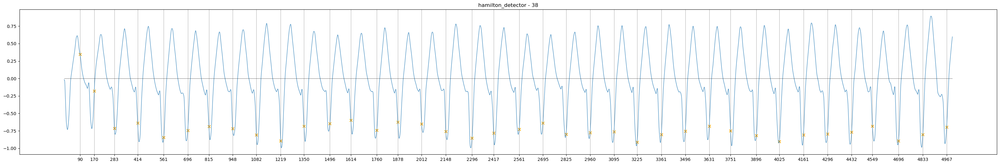

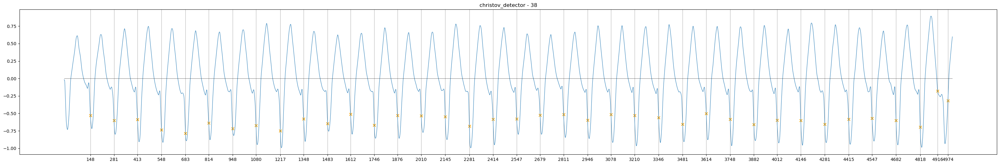

IndexError: pop from empty list

In [43]:
for a, b in denoisedGLOBAL20.items():
    example = denoisedGLOBAL20[a][:150000]
    example_5000 = example[:5000]

    for kd in detectors.keys():
        vd = detectors[kd]
        r_peaks = np.array(vd[0](np.hstack((signal_pad,example_5000)))) - signal_pad_samples
        vd[1] = r_peaks
        plt.figure(figsize=(40,6))
        plt.title(f'{kd} - {a}')
        plt.plot(example_5000,color='tab:blue',linewidth=0.8)
        data_peaks_4 = detecs['engzee_detector'][1]
        plt.scatter(r_peaks, example_5000[r_peaks], color='orange', marker='x', label='R-peaks')
        plt.hlines(0,0,5000,color='black', linewidth=0.4)
        plt.xticks(r_peaks)
        plt.grid(axis='x')
        plt.show()